In [1]:
# load packages
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

In [12]:
ds = xr.open_dataset("/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_land_mon_avg.nc")
# soil water storage (sws) = volumetric water content x layer thickness
sws = (
    ds['swvl1'] * 0.07 +
    ds['swvl2'] * 0.21 +
    ds['swvl3'] * 0.72 +
    ds['swvl4'] * 1.89
)
sws = sws * 1000
sws.attrs["units"] = "mm"
sws.name = "sws"

<xarray.Dataset> Size: 118GB
Dimensions:     (valid_time: 912, latitude: 1801, longitude: 3600)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2025-12-01
  * latitude    (latitude) float64 14kB 90.0 89.9 89.8 ... -89.8 -89.9 -90.0
  * longitude   (longitude) float64 29kB 0.0 0.1 0.2 0.3 ... 359.7 359.8 359.9
    number      int64 8B ...
    expver      (valid_time) <U4 15kB ...
Data variables:
    swvl1       (valid_time, latitude, longitude) float32 24GB ...
    swvl2       (valid_time, latitude, longitude) float32 24GB ...
    swvl3       (valid_time, latitude, longitude) float32 24GB ...
    swvl4       (valid_time, latitude, longitude) float32 24GB ...
    tp          (valid_time, latitude, longitude) float32 24GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-02-03T22:46 GRIB to CDM+CF via cfgrib-0.9.1...

In [3]:
sws = sws.rename({
    'valid_time': 'time',
    'latitude': 'lat',
    'longitude': 'lon'
})

sws = sws.sortby('lat')
sws = sws.assign_coords(
    lon = (((sws.lon + 180) % 360) - 180)
).sortby('lon')
sws = sws.sel(time=slice("1950-01-01", "2024-12-31"))
sws

<xarray.DataArray 'sws' (time: 900, lat: 1801, lon: 3600)> Size: 23GB
array([[[498.07614, 498.07614, 498.07614, ..., 498.07614, 498.07614,
         498.07614],
        [480.19894, 480.16873, 480.1254 , ..., 480.5522 , 480.3999 ,
         480.24332],
        [480.16354, 480.11136, 480.0659 , ..., 480.51465, 480.36023,
         480.20795],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[498.08344, 498.08344, 498.08344, ..., 498.08344, 498.08344,
         498.08344],
        [480.20624, 480.17603, 480.1327 , ..., 480.55948, 480.4072 ,
         480.25067],
        [480.17084, 480.11865, 480.07318, ..., 480.52194, 480.36755,
         480.21524],
...
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]],

       [[509.04572, 509.04572, 509.04572, ..., 509.04572, 509.04572,
         509.04572],
        [480.2037 , 480.1735 , 480.13016, ..., 480.55698, 480.40466,
         480.2481 ],
        [480.1683 , 480.11612, 480.07065, ..., 480.5194 , 480.36502,
         480.2127 ],
        ...,
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan]]], shape=(900, 1801, 3600), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2024-12-01
  * lat      (lat) float64 14kB -90.0 -89.9 -89.8 -89.7 ... 89.7 89.8 89.9 90.0
  * lon      (lon) float64 29kB -179.9 -179.8 -179.7 ... 179.8 179.9 180.0
    number   int64 8B 0
    expver   (time) <U4 14kB '0001' '0001' '0001' ... '0001' '0001' '0001'
Attributes:
    units:    mm

In [4]:
sws.min().compute()

<xarray.DataArray 'sws' ()> Size: 8B
array(-2.22891558e-17)
Coordinates:
    number   int64 8B 0

In [5]:
sws.max().compute()

<xarray.DataArray 'sws' ()> Size: 8B
array(2209.66894531)
Coordinates:
    number   int64 8B 0

In [17]:
lat = sws.lat
lon = sws.lon
print(abs(lat[1] - lat[0]).values)
print(abs(lon[1] - lon[0]).values)

0.1000000000016712
0.0999999999999659


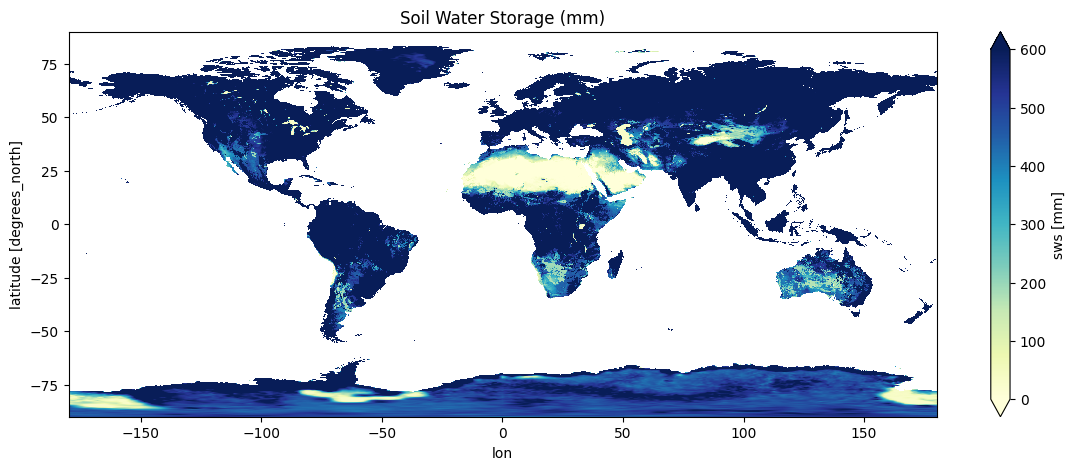

In [6]:
sws.isel(time=-1).plot(
    cmap="YlGnBu",
    figsize=(14,5),
    vmin=0,
    vmax=600   # typical soil water range
)

plt.title("Soil Water Storage (mm)")
plt.show()

In [7]:
sws.to_netcdf("/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed/sws.nc")